# 02 - Salario mínimo: Región 1 vs Región 2

Fuente: Gaceta Oficial (DE 75/2017 → 2019, DE 74/2021 → 2022, DE 13/2025 → 2026).
Comercio al por menor: tasa por hora; mensual = hora × 208. Trabajo doméstico: mensual oficial del decreto.
Este notebook **no** cruza la Región 2 con la canasta.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

P = Path("..") / "data" / "processed"
FIG = Path("..") / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

salario = pd.read_csv(P / "salario_minimo.csv", parse_dates=["fecha_inicio"])
salario["region"] = salario["region"].astype(int)

ANIOS = [2019, 2022, 2026]
ETIQ = {"pequena": "Comercio\npequeña empresa",
        "gran_empresa": "Comercio\ngran empresa",
        "supermercados_5_plus": "Comercio\nsupermercados 5+",
        "domestico": "Trabajo\ndoméstico"}
COLOR = {1: "#1428A0", 2: "#8FA0E0"}   # R1 azul Samsung, R2 azul claro

salario.head()

,fecha_inicio,anio_analisis,decreto,region,actividad,categoria,salario_hora,salario_mensual,es_oficial_mensual,categoria_existia
0,2018-01-01,2019,DE 75/2017,1,comercio_al_por_menor,pequena,2.20,457.60,False,True
1,2018-01-01,2019,DE 75/2017,1,comercio_al_por_menor,gran_empresa,2.72,565.76,False,True
2,2018-01-01,2019,DE 75/2017,2,comercio_al_por_menor,pequena,1.84,382.72,False,True
3,2018-01-01,2019,DE 75/2017,2,comercio_al_por_menor,gran_empresa,2.23,463.84,False,True
4,2022-01-16,2022,DE 74/2021,1,comercio_al_por_menor,pequena,2.27,472.16,False,True


## 1. Revisión rápida de la tabla

In [2]:
print(salario.shape)
print(salario.groupby(["anio_analisis", "region"]).size().unstack())
salario.isna().sum()

(22, 10)
region         1  2
anio_analisis      
2019           3  3
2022           4  4
2026           4  4


fecha_inicio          0
anio_analisis         0
decreto               0
region                0
actividad             0
categoria             0
salario_hora          6
salario_mensual       0
es_oficial_mensual    0
categoria_existia     0
dtype: int64

## 2. Tabla ancha: salario mensual por categoría, año y región

In [3]:
ancho = salario.pivot_table(index=["categoria", "anio_analisis"],
                            columns="region", values="salario_mensual")
ancho.columns = ["R1", "R2"]
ancho["brecha_B/."] = ancho["R1"] - ancho["R2"]
ancho["brecha_%_sobre_R2"] = (ancho["R1"] / ancho["R2"] - 1) * 100
ancho.round(2)

R1      R2  brecha_B/.  \
categoria            anio_analisis                               
domestico            2019           275.00  250.00       25.00   
                     2022           315.00  290.00       25.00   
                     2026           350.00  320.00       30.00   
gran_empresa         2019           565.76  463.84      101.92   
                     2022           584.48  478.40      106.08   
                     2026           628.16  515.84      112.32   
pequena              2019           457.60  382.72       74.88   
                     2022           472.16  395.20       76.96   
                     2026           492.96  413.92       79.04   
supermercados_5_plus 2022           599.04  490.88      108.16   
                     2026           642.72  528.32      114.40   

                                    brecha_%_sobre_R2  
categoria            anio_analisis                     
domestico            2019                       10.00  
                     2022                        8.62  
                     2026                        9.38  
gran_empresa         2019                       21.97  
                     2022                       22.17  
                     2026                       21.77  
pequena              2019                       19.57  
                     2022                       19.47  
                     2026                       19.10  
supermercados_5_plus 2022                       22.03  
                     2026                       21.65

## 3. Evolución del salario en el tiempo (2019 → 2022 → 2026)

In [4]:
def cambio(df, col="salario_mensual"):
    p = df.pivot_table(index="anio_analisis", columns=["categoria", "region"], values=col)
    out = pd.DataFrame({
        "2019→2022 %": (p.loc[2022] / p.loc[2019] - 1) * 100,
        "2022→2026 %": (p.loc[2026] / p.loc[2022] - 1) * 100,
        "2019→2026 %": (p.loc[2026] / p.loc[2019] - 1) * 100,
    })
    return out

cambios = cambio(salario)
cambios.round(1)

2019→2022 %  2022→2026 %  2019→2026 %
categoria            region                                       
domestico            1              14.5         11.1         27.3
                     2              16.0         10.3         28.0
gran_empresa         1               3.3          7.5         11.0
                     2               3.1          7.8         11.2
pequena              1               3.2          4.4          7.7
                     2               3.3          4.7          8.2
supermercados_5_plus 1               NaN          7.3          NaN
                     2               NaN          7.6          NaN

> Supermercados 5+ no existe en 2019, por eso sus columnas con 2019 salen vacías (NaN). Es esperado, no un error.

## 4. Figura 1 - Salario mensual por categoría (R1 vs R2, tres años)

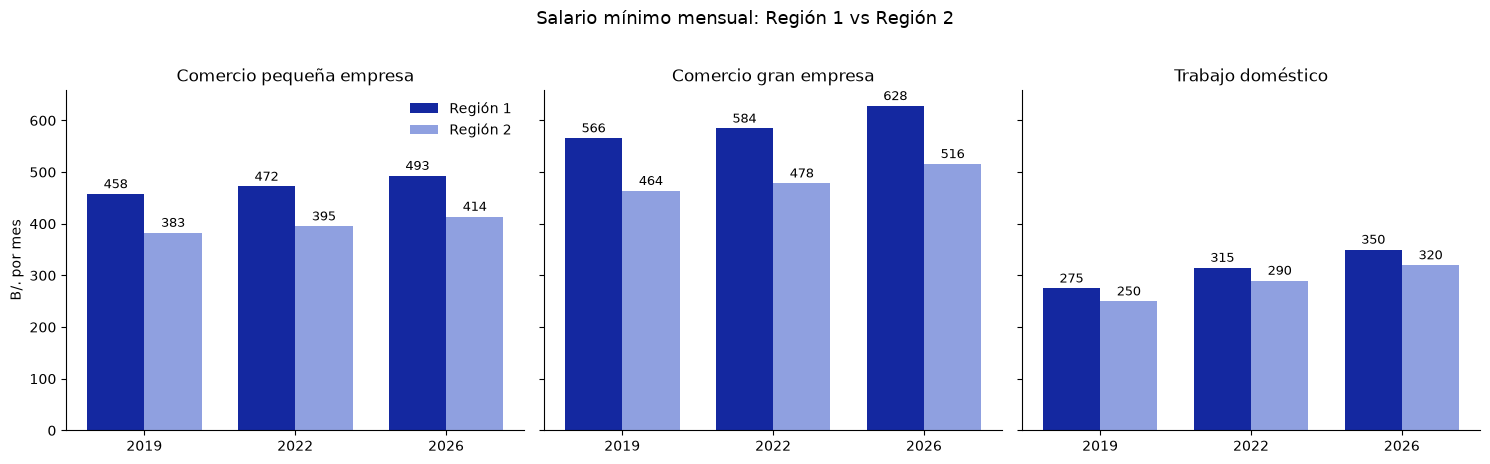

In [5]:
cats = ["pequena", "gran_empresa", "domestico"]   # existen en los tres años
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
w = 0.38
for ax, cat in zip(axes, cats):
    sub = salario[salario.categoria == cat]
    x = np.arange(len(ANIOS))
    for k, reg in enumerate([1, 2]):
        vals = (sub[sub.region == reg].set_index("anio_analisis")
                   .reindex(ANIOS)["salario_mensual"])
        bars = ax.bar(x + (k - 0.5) * w, vals, w, color=COLOR[reg], label=f"Región {reg}")
        ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(ANIOS)
    ax.set_title(ETIQ[cat].replace("\n", " "))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("B/. por mes")
axes[0].legend(frameon=False)
fig.suptitle("Salario mínimo mensual: Región 1 vs Región 2", y=1.02, fontsize=13)
fig.tight_layout()
fig.savefig(FIG / "salario_r1_vs_r2.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Figura 2 - Brecha entre regiones (B/. y %)

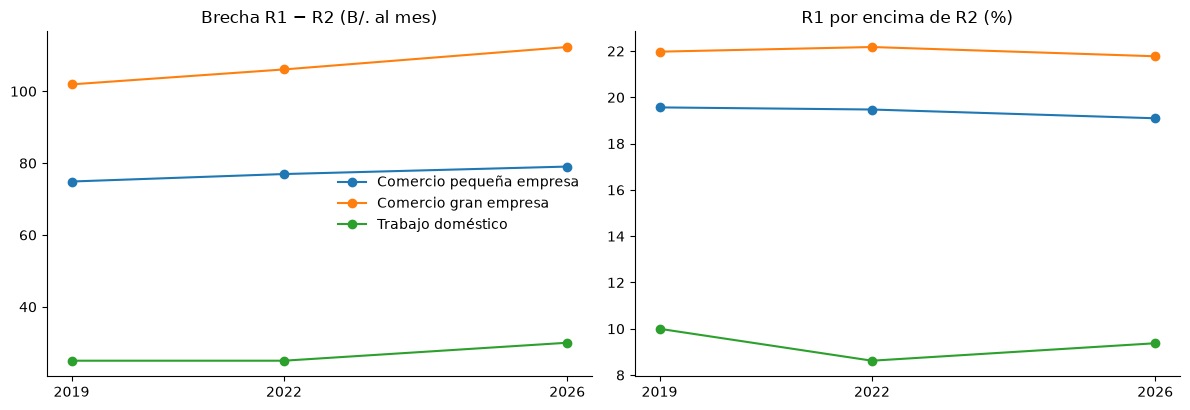

In [6]:
b = ancho.reset_index()
b = b[b.categoria.isin(cats)]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
for i, cat in enumerate(cats):
    d = b[b.categoria == cat].set_index("anio_analisis").reindex(ANIOS)
    a1.plot(ANIOS, d["brecha_B/."], marker="o", label=ETIQ[cat].replace("\n", " "))
    a2.plot(ANIOS, d["brecha_%_sobre_R2"], marker="o", label=ETIQ[cat].replace("\n", " "))
a1.set_title("Brecha R1 − R2 (B/. al mes)"); a2.set_title("R1 por encima de R2 (%)")
for a in (a1, a2):
    a.set_xticks(ANIOS); a.spines[["top", "right"]].set_visible(False)
a1.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "brecha_r1_r2.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Figura 3 - Aumento porcentual del salario por categoría (Región 1 y 2)

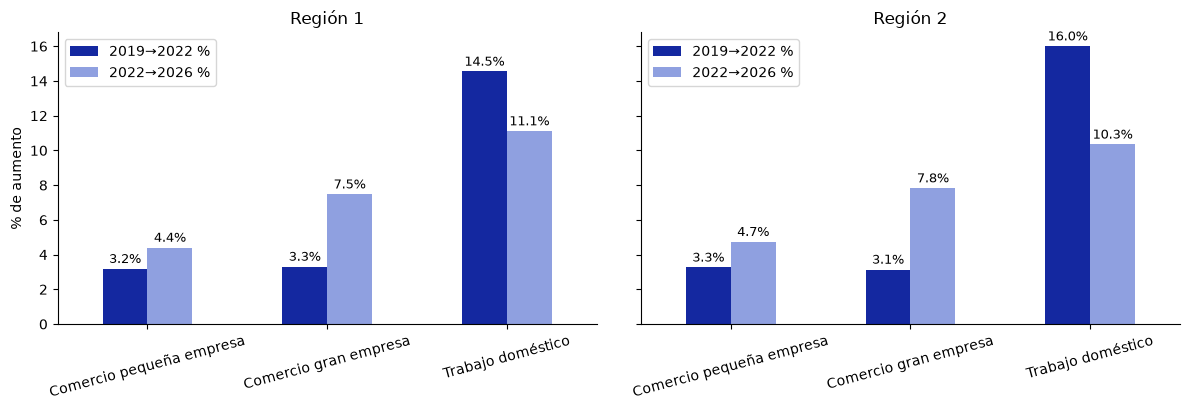

In [7]:
inc = cambios.loc[cats, ["2019→2022 %", "2022→2026 %"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, reg in zip(axes, [1, 2]):
    d = inc.xs(reg, level="region")
    d.index = [ETIQ[c].replace("\n", " ") for c in d.index]
    d.plot.bar(ax=ax, rot=15, color=["#1428A0", "#8FA0E0"])
    ax.set_title(f"Región {reg}"); ax.set_ylabel("% de aumento")
    ax.spines[["top", "right"]].set_visible(False)
    for c in ax.containers: ax.bar_label(c, fmt="%.1f%%", padding=2, fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "aumento_salario_por_periodo.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Supermercados 5+ (solo 2022 y 2026)

In [8]:
sup = salario[salario.categoria == "supermercados_5_plus"]
comp = sup.pivot_table(index="anio_analisis", columns="region", values="salario_mensual")
comp["prima_vs_gran_empresa_R1_%"] = (
    comp[1] / salario[(salario.categoria == "gran_empresa") & (salario.region == 1)]
    .set_index("anio_analisis")["salario_mensual"] - 1) * 100
comp.round(2)

region,1,2,prima_vs_gran_empresa_R1_%
anio_analisis,,,
2022,599.04,490.88,2.49
2026,642.72,528.32,2.32


## 8. Inferencias (revisar y ajustar con tus propias palabras)

In [9]:
r = lambda cat, reg, a: float(salario[(salario.categoria == cat) & (salario.region == reg)
                                      & (salario.anio_analisis == a)]["salario_mensual"].iloc[0])
for cat in cats:
    for reg in (1, 2):
        a, b_, c = r(cat, reg, 2019), r(cat, reg, 2022), r(cat, reg, 2026)
        print(f"{cat:13s} R{reg}: {a:7.2f} → {b_:7.2f} → {c:7.2f}  "
              f"(+{(b_/a-1)*100:.1f}% y +{(c/b_-1)*100:.1f}%, total +{(c/a-1)*100:.1f}%)")
print()
for cat in cats:
    print(f"Brecha R1-R2 {cat:13s}:", [round(r(cat,1,a)-r(cat,2,a), 2) for a in ANIOS], "B/.")

pequena       R1:  457.60 →  472.16 →  492.96  (+3.2% y +4.4%, total +7.7%)
pequena       R2:  382.72 →  395.20 →  413.92  (+3.3% y +4.7%, total +8.2%)
gran_empresa  R1:  565.76 →  584.48 →  628.16  (+3.3% y +7.5%, total +11.0%)
gran_empresa  R2:  463.84 →  478.40 →  515.84  (+3.1% y +7.8%, total +11.2%)
domestico     R1:  275.00 →  315.00 →  350.00  (+14.5% y +11.1%, total +27.3%)
domestico     R2:  250.00 →  290.00 →  320.00  (+16.0% y +10.3%, total +28.0%)

Brecha R1-R2 pequena      : [74.88, 76.96, 79.04] B/.
Brecha R1-R2 gran_empresa : [101.92, 106.08, 112.32] B/.
Brecha R1-R2 domestico    : [25.0, 25.0, 30.0] B/.
